In [52]:
from anemone.forwards import *
import matplotlib.pyplot as plt
import numpy as np
import torch
import scipy as sp

# %%
from physics import rte_raiche1999 as rte
from physics import rte_halfspace, drte_dsigma

# %%
def make_H2t(t2t, geomz, omega, lmb, tolerance=1e-6, sigma_ref=0.01):
    # if t_indices is None:
    t_indices = np.arange(t2t.shape[0])

    t1 = (t2t[0, :, None]*geomz.real[None, :]).numpy()
    full_mask = np.zeros_like(t1, dtype=bool)

    rte_ref = rte_halfspace(torch.tensor(sigma_ref), omega[:,None], lmb[None,:]).squeeze().cpu().numpy()

    for i in t_indices:
        t1 = (t2t[i, :, None]*geomz.real[None, :]).numpy()*rte_ref
        t1_shape = t1.shape
        t1sort = np.abs(t1).flatten()
        # indices = np.arange(len(t1sort))

        sort_idx = np.argsort(t1sort)
        t1sort = t1sort[sort_idx]
        t1cumsum = np.cumsum(t1sort)
        t1cumsum /= t1cumsum[-1]
        idx = np.searchsorted(t1cumsum, tolerance)#-1

        mask = np.zeros_like(t1sort, dtype=bool)
        mask[idx:] = True


        inv_sort = np.argsort(sort_idx)
        mask = mask[inv_sort].reshape(t1_shape)
        full_mask += mask
    
    omega_i = np.arange(omega.squeeze().shape[0])
    lamda_i = np.arange(lmb.squeeze().shape[0])
    omega_i, lamda_i = np.meshgrid(omega_i, lamda_i, indexing='ij')

    omega_i = omega_i[full_mask]
    lamda_i = lamda_i[full_mask]
    # print(omega_i.min(), omega_i.max(), lamda_i.min(), lamda_i.max())
    print('n omegas: ', omega_i.max()-omega_i.min())
    print('n lambdas: ', lamda_i.max()-lamda_i.min())

    # full_mask[:,:] = False
    # full_mask[int(omega_i.min()):int(omega_i.max()), int(lamda_i.min()):int(lamda_i.max())] = True

    H2t = np.zeros(t2t.shape[:1]+(full_mask.sum(),), dtype=complex)

    for i in range(t2t.shape[0]):
        t1 = (t2t[i, :, None]*geomz.real[None, :]).numpy()
        H2t[i] = t1[full_mask].flatten()

    H2tweight = np.abs(H2t).sum(0)#.numpy()

    idx_H2t = np.argsort(H2tweight)[::-1]
    H2t = H2t[:, idx_H2t]

    Omega,Lambda = np.meshgrid(omega.squeeze().cpu().numpy(), lmb.squeeze().cpu().numpy(), indexing='ij')
    Omega = Omega[full_mask]
    Lambda = Lambda[full_mask]
    return torch.tensor(H2t), torch.tensor(Omega[idx_H2t])+0j, torch.tensor(Lambda[idx_H2t])+0j

class ForwardFlow(Forward):
    geomz = None
    t2t   = None

    def __init__(self, source, receiver, times, waveform=None, filterfunc=None, t_gatewidth=None, tolerance=1e-7):
        device = times.device

        super().__init__(source, receiver, times.cpu(), waveform, filterfunc, t_gatewidth, tolerance, precalc=False)
        self.t2t = None
        self.setup()
        self.device=device
        self.H2t = self.H2t.to(self.device).to(torch.complex64)
        self.omega = self.omega.to(self.device).to(torch.complex64)
        self.lmb = self.lmb.to(self.device).to(torch.complex64)
        self.H2tjac = self.H2t.to(self.device).to(torch.complex64)


    def setup(self):
        self.rho   = 40*torch.ones(2)[:, None, None] + 0j
        self.thick = 20*torch.ones(1)[:, None, None] + 0j

        def frq_integrand(f):
            self.omega = c.twopi*f[None,:,None]
            def wvlngth_integrand(wave_length):
                """ Hz from horizontal electric dipole. """
                self.lmb = wave_length[None, None, :]          
                #self.tmp_u0 = u0(self.omega, self.lmb)
                self.sfield_rte = torch.exp(-self.lmb*self.sfield_dz)*self.lmb / c.fourpi
                intg = rte(self.sigma, self.thick, self.omega, self.lmb)*self.sfield_rte
                return intg.squeeze()
            hkl1 = Hankel(wvlngth_integrand, 1, device=self.device)
            def geomz_r(r):
                return self.source.geomz(self.receiver, r).to(torch.double).to(self.device)
            Hr, self.geomz, self.lmb = hkl1.preintegrate(geomz_r, self.rmin, self.rmax)
            
            self.geomz *= torch.exp(-self.lmb*self.sfield_dz)*self.lmb / c.fourpi

            return Hr.squeeze()
        
        if self.t2t is None:
            self.cbft=invFourier(frq_integrand, device=self.device)
            def t2t_func(t_in):
                if self.t_gatewidth is not None:
                    waveform_matrix = wv_to_t(t_in, t_in, waveform=self.waveform)
                    gate_matrix = gating_matrix(t_in, self.t_st, self.t_end, n_eval=1000)
                    return gate_matrix @ waveform_matrix
                else:
                    return wv_to_t(self.times, t_in, waveform=self.waveform)

            
            Ht, self.t2t, self.omega1 = self.cbft.preintegrate(t2t_func, self.tmin, self.tmax*100.)
            scalar = self.times**(5/2)
            self.scalar = scalar/scalar.min()
            # self.t2t *= self.scalar[:, None]

            if self.filterfunc is not None:
                self.t2t *= self.filterfunc.omega_filter(self.omega1.squeeze())
            if self.waveform is not None:
                self.t2t /= -1j#*self.omega1.squeeze()
            else:
                self.t2t *= self.omega1.squeeze()

        self.H2t, self.omega, self.lmb = make_H2t(self.t2t, self.geomz, self.omega1, self.lmb, tolerance=self.tolerance)

        self.H2t       = self.H2t.to(self.device).to(torch.complex64)
        self.H2t      /= torch.sqrt(self.omega)
        self.H2t      /= c.sqrt_twopi
        self.omega    *= c.sqrt_twopi
        self.H2tjac    = self.H2t[:, None, :].to(self.device)                                   #[:, :3*len(self.omega)//6]
        # self.omegajac  = self.omega                                  #[:3*len(self.omega)//6]
        # self.lmbjac    = self.lmb                                    #[:3*len(self.omega)//6]
    
    def forward(self):
        with torch.no_grad():
            cRTE = rte(self.sigma, self.thick, self.omega, self.lmb).squeeze()
            return torch.einsum('ik,...k->i...', self.H2t, cRTE).real

    def jacobian(self):
        dRTE = drte_dsigma(self.sigma, self.thick, self.omega, self.lmb).squeeze()
        
        if len(dRTE.shape)>2:
            Gr = torch.einsum('ijk,lk->jil', dRTE, self.H2tjac).real
            # print(Gr.shape)
            # print(self.rho.squeeze().shape)
            Gr /= (self.rho.real.squeeze().T**2)[:,:,None]
        else:
            Gr = torch.einsum('ik,...k->i...', dRTE.real, self.H2t.real) - torch.einsum('ik,jk->ij', dRTE.imag, self.H2t.imag)
            Gr /= (self.rho.real.squeeze()**2)[:,None]
        return Gr
    
    def __call__(self, rho, thickness, jac=False):
        with torch.no_grad():
            if not isinstance(rho, torch.Tensor):       rho       = torch.tensor(rho)
            if not isinstance(thickness, torch.Tensor): thickness = torch.tensor(thickness)        
            self.rho = ((rho+0j)[..., None, None]).to(torch.complex64)#.to(self.device)
            if rho.ndim > thickness.ndim:
                thickness = thickness[:, None, ...]
            self.thick = ((thickness+0j)[..., None, None]).to(torch.complex64)
            if jac:
                G = self.jacobian()
                return G*c.mu0
            else:            
                return self.forward()*c.mu0     

    def copy(self):
        from copy import deepcopy
        return deepcopy(self)   

In [53]:
fwr = ForwardFlow.example(times=torch.logspace(-5, -3, 32))#, tolerance=1e-6)

n omegas:  103
n lambdas:  57


In [119]:
rho = torch.ones(31)*40.
thk = torch.logspace(0, 1, len(rho)-1)
thk *= 150./thk.sum()

rho[10:20] = 80.
rho_true = rho.clone()

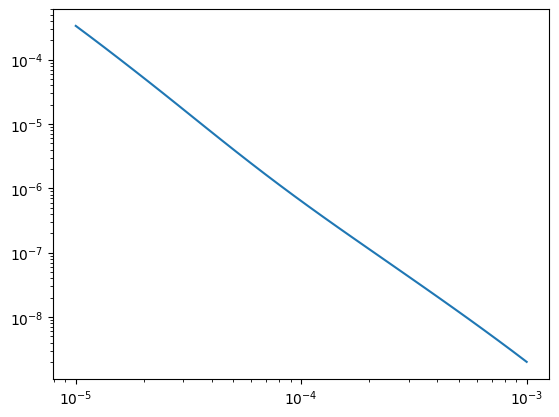

In [120]:
dbdt_true = fwr(rho, thk).numpy()

plt.figure()
plt.loglog(fwr.times, dbdt_true)

In [121]:
rho = torch.ones(31)*40.
G = fwr(rho, thk, jac=True).numpy()
dbdt = fwr(rho, thk).numpy()
G /= dbdt
G.T[:,:] *= rho.numpy()
G = G.T

<Figure size 640x480 with 0 Axes>

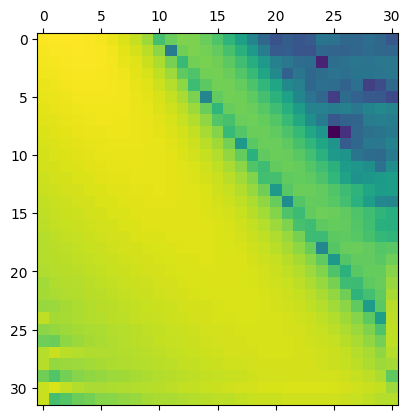

In [122]:
plt.figure()
plt.matshow(np.log10(np.abs(G)))

In [123]:
Cdi = 1./np.log1p(0.03*np.ones_like(dbdt))**2
GtG = (G.T*Cdi) @ G

C:\Users\au646858\AppData\Local\Temp\14\ipykernel_28028\3162251158.py:1: RuntimeWarning: invalid value encountered in log10
  pcm=plt.matshow(np.log10(GtG))


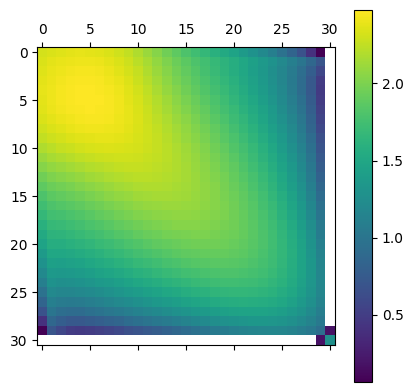

In [124]:
pcm=plt.matshow(np.log10(GtG))
plt.colorbar(pcm)

In [125]:
from numpy.linalg import svd, lstsq, solve, inv

In [126]:
damp = np.eye(GtG.shape[0])*20.

In [127]:
r_data = G.T @ (Cdi*(dbdt_true-dbdt))

time:  6.83
99


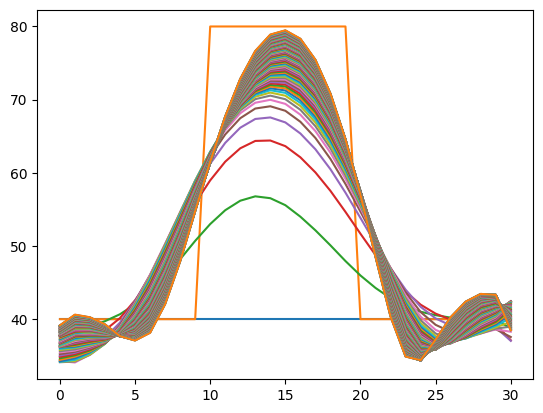

In [128]:
from time import time as timer
rho = torch.ones(31)*40.

Cdi = 1./(0.03*dbdt_true)**2
plt.figure()
plt.plot(rho)
plt.plot(rho_true)

bt = timer()
for i in range(100):

    G = fwr(rho, thk, jac=True).numpy()
    dbdt = fwr(rho, thk).numpy()
    G = G.T

    GtG = (G.T*Cdi) @ G    
    r_data = G.T @ (Cdi*(dbdt_true-dbdt))
    damp_f = 0.1#(10*(0.9**i))
    damp = np.eye(GtG.shape[0])*damp_f
    Ainv = inv(GtG+damp)
    dM = Ainv @ r_data
    dM = solve(GtG+damp, r_data)
    # if np.all(np.abs(dM)<0.1):
    #     break
    rho = rho + dM
    plt.plot(rho)
print(f'time:  {timer()-bt:0.2f}')
print(i)

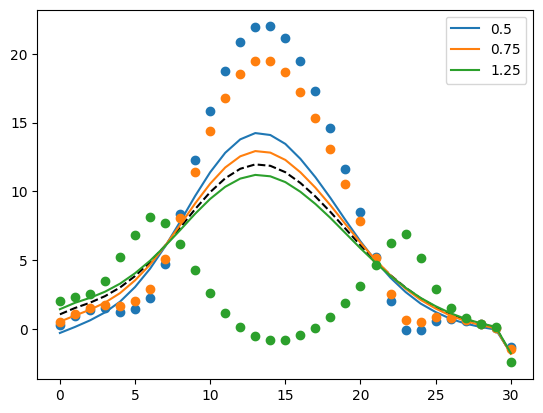

In [129]:
from time import time as timer
rho = torch.ones(31)*40.

Cdi = 1./(0.03*dbdt_true)**2
# plt.figure()
# plt.plot(rho)
# plt.plot(rho_true)


G = fwr(rho, thk, jac=True).numpy()
dbdt = fwr(rho, thk).numpy()
G = G.T

GtG = (G.T*Cdi) @ G    
r_data = G.T @ (Cdi*(dbdt_true-dbdt))
damp_f1 = 0.5
damp = np.eye(GtG.shape[0])*damp_f1
Ainv1 = inv(GtG+damp)
dM1 = Ainv1 @ r_data

plt.figure()
plt.plot(dM1, 'k--')

for i,dampf in enumerate([0.5, 0.75, 1.25]):
    damp_f2 = dampf*damp_f1
# damp_f2 = 0.51
    damp = np.eye(GtG.shape[0])*damp_f2
    Ainv2 = inv(GtG+damp)
    dM2 = Ainv2 @ r_data

    dM1to2 = dM1 + -2.*damp_f2*Ainv@dM1*(damp_f2-damp_f1)

    plt.plot(dM2, f'C{i}', label=dampf)
    plt.plot(dM1to2, f'C{i}o')
plt.legend()

In [130]:
u,sgm,v = svd(GtG, full_matrices=True)

In [131]:
from time import time as timer
rho = torch.ones(31)*40.

Cdi = 1./(0.03*dbdt_true)**2
# Cdi = np.ones_like(dbdt_true)
# plt.figure()
# plt.plot(rho)
# plt.plot(rho_true)


G = fwr(rho, thk, jac=True).numpy()
dbdt = fwr(rho, thk).numpy()
G = G.T

GtG = (G.T*Cdi) @ G    
r_data = G.T @ (Cdi*(dbdt_true-dbdt))
damp_f1 = 0.3
damp = np.eye(GtG.shape[0])*damp_f1
# Ainv1 = inv(GtG+damp)
# dM1 = Ainv1 @ r_data
dM1 = solve(GtG+damp, r_data)

u,sgm,v = svd(GtG, full_matrices=True)

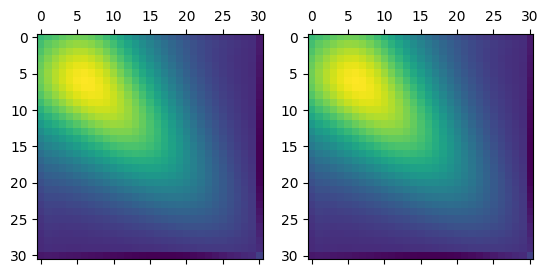

In [132]:
u,sgm,v = svd(GtG, full_matrices=True)
GtG_svd = u@np.diag(sgm)@v

fig,axs = plt.subplots(1,2)
axs[0].matshow(GtG)
axs[1].matshow(GtG_svd)

In [133]:
np.log(3)

1.0986122886681098

old damp: 0.1
[-2.29175091e+00 -3.02025676e-02  7.47201219e-02  8.27907622e-02
  8.32642391e-02  8.33407864e-02  8.33445862e-02  8.32830444e-02
  8.37641582e-02  8.66706148e-02  5.88742308e-02  1.96063984e-02
  1.20641440e-02  1.61747390e-03  9.76512500e-04 -5.02107432e-04
  8.61617300e-05  1.84107875e-03  1.07858114e-05 -1.28527055e-04
  7.13378768e-06 -3.81460654e-06 -3.97307667e-05  1.43892466e-05
  3.73391958e-06 -2.15141526e-07  3.12132920e-06 -8.50351398e-08
 -1.03628246e-07 -1.46158456e-07 -4.98036945e-10]
new damp: 9.765124996192753e-05


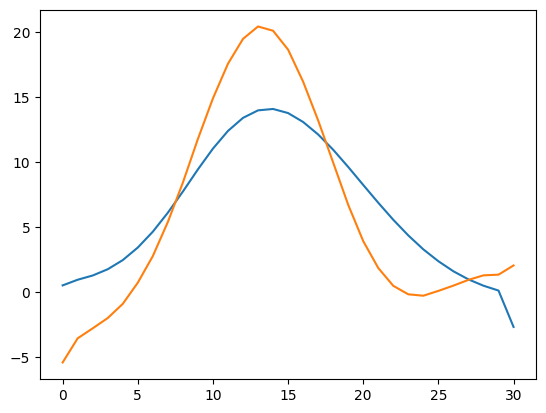

In [134]:
u,sgm,v = svd(GtG, full_matrices=True)

plt.figure()
damp_f = 0.1

damp = sgm / (sgm**2 + damp_f)
damp = np.diag(damp)
print(f'old damp: {damp_f}')

c1 = u.T @ r_data
dMsvd = v.T @ damp @ c1
idM = np.argmax(np.abs(dMsvd))
plt.plot(dMsvd)

dMsvd *= 1.2

d = v@(dMsvd)
lmb = (sgm*c1)/d - sgm**2

print(lmb)


damp_f = lmb[idM]/10.


print(f'new damp: {damp_f}')
damp = sgm / (sgm**2 + damp_f)
damp = np.diag(damp)

c1 = u.T @ r_data
dMsvd = v.T @ damp @ c1


plt.plot(dMsvd)

In [135]:
rel_err

array([0.03000154, 0.03000278, 0.03000501, 0.03000908, 0.03001649,
       0.03003013, 0.03005554, 0.03010346, 0.03019475, 0.03036936,
       0.03070447, 0.03134741, 0.03257114, 0.03485521, 0.03897094,
       0.04602195, 0.05741202, 0.07482024, 0.10028854, 0.1364152 ,
       0.1866939 , 0.2560077 , 0.35082704, 0.47920385, 0.652397  ,
       0.88618064, 1.2024314 , 1.6309029 , 2.216372  , 3.0198724 ,
       4.1267834 , 5.6734424 ], dtype=float32)

misfits:  [49.30341095092651, 18.822698923211806, 6.0549570768337375, 1.6674220854411075, 1.0934705415090107, 1.1152338383116704, 1.1085550683702547, 1.0931077678640895, 1.0733210914087388, 1.051599773057836, 1.0361456410038905, 1.0172510003577149, 1.0172353217239225]
damp_f [0.0027699424743652342, 0.18767746027252866, 0.060111462173350345, 6.964949649726187e-05, 6.964949649726187e-05, 0.0006964949649726187, 0.0006964949649726187, 0.0006964949649726187, 0.0006802988516702601, 0.0006802988516702601, 0.0006802988516702601, 4.999081762827257e-05, 77511103.56968808]
target_step:  [0.05, 1.6193592721247032, 1.897778550025515, 2.1313759569688466, 0.3826446709292083, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01]
time:  0.85
12


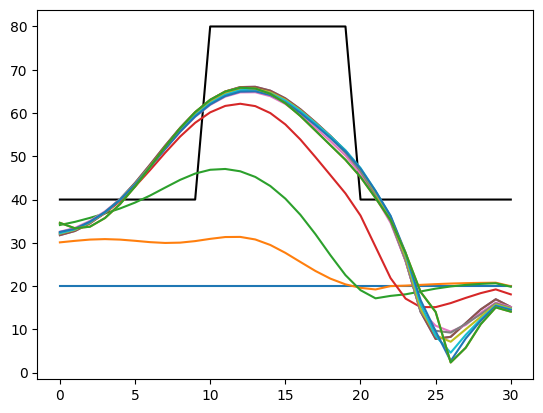

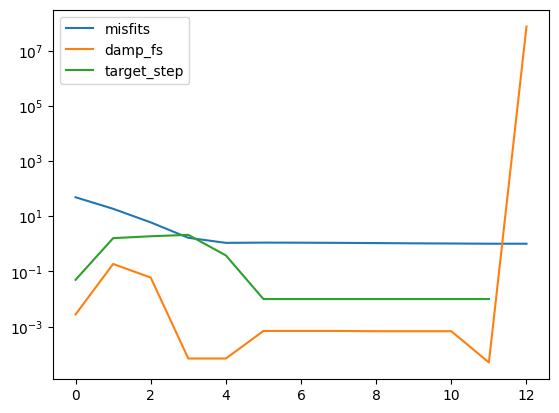

In [ ]:
def compute_relstd(t_gates, data_val, noise_slope_exponent=-0.5, noise_level_at_1ms=1e-8, current=1, relative_noise=0.03):
    b = noise_level_at_1ms/(1e-3**noise_slope_exponent)
    abs_noise = b*(t_gates**noise_slope_exponent)
    y = data_val*current
    std_rel = abs_noise/y.T
    relstd_tot = (std_rel**2 + relative_noise**2)**0.5
    return relstd_tot

from time import time as timer
rho = torch.ones(31)*20.


# dbdt_true = dbdt_true.numpy()

rel_err = compute_relstd(fwr.times, dbdt_true).numpy()
d_obs = dbdt_true + rel_err*dbdt_true*np.random.randn(len(dbdt_true))

Cdi = 1./(rel_err*dbdt_true)**2

# damp_f = 0.1

bt = timer()

plt.figure()
plt.plot(rho_true, 'k-')
plt.plot(rho)

def misfit(dpred):
    return ((Cdi*(d_obs-dpred)**2).sum()/ len(dpred))**0.5 

misfits = []

target_step = [0.05]

dbdt = fwr(rho, thk).numpy()
misfits.append(misfit(dbdt))
damp_fs = []

for i in range(100):
    G = fwr(rho, thk, jac=True).numpy()
    
    G = G.T
    

    GtG = (G.T*Cdi) @ G    
    if i==0:
        damp_fs.append(GtG.diagonal().max()/2500.)
    r_data = G.T @ (Cdi*(d_obs-dbdt))

    u,sgm,v = svd(GtG, full_matrices=True)
    damp = sgm / (sgm**2 + damp_fs[-1])
    damp = np.diag(damp)

    c1 = u.T @ r_data
    dMsvd = v.T @ damp @ c1
    reldM = np.abs(dMsvd)/rho.numpy()

    if reldM.max() < 0.005:
        break

    idM = np.argmax(np.abs(reldM))
    norm = target_step[-1]/reldM[idM]
    dMsvd *= norm
    d = v@(dMsvd)
    cdamp = ((sgm*c1)/d - sgm**2)[idM]
    damp_fs.append(cdamp if cdamp>0 else damp_fs[-1])

    damp = sgm / (sgm**2 + damp_fs[-1])
    damp = np.diag(damp)

    c1 = u.T @ r_data
    dMsvd = v.T @ damp @ c1
    reldM = np.abs(dMsvd)/rho.numpy()


    

    rho = rho+dMsvd
    dbdt = fwr(rho, thk).numpy()
    misfits.append(misfit(dbdt))
    dMisfit = (misfits[-2]-misfits[-1])/misfits[-1]
    if dMisfit>0:
        damp_fs[-1] *= 10.
        rho = rho-dMsvd
        # target_step.append(target_step[-1]/10.)
    else:
        target_step.append(max(0.01, np.abs(dMisfit*0.9**i)))
    

    
    # if i%5==0:
    plt.plot(rho)
print('misfits: ', misfits)
print('damp_f', damp_fs)
print('target_step: ', target_step)


print(f'time:  {timer()-bt:0.2f}')
print(i)

plt.figure()
plt.semilogy(misfits, label='misfits')
plt.semilogy(damp_fs, label='damp_fs')
plt.semilogy(target_step, label='target_step')
plt.legend()

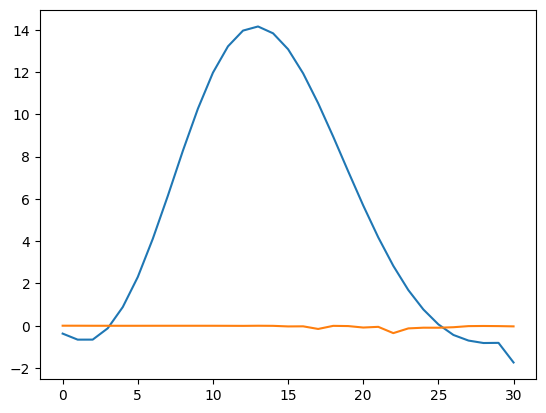

In [114]:
plt.figure()
plt.plot(dM1)
plt.plot(dMsvd)